Import libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
sales = pd.read_csv(
    "../data/raw/ecommerce_sales_customer_analytics_150k.csv"
)

In [3]:
sales.shape

(138116, 46)

In [4]:
sales.head()

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [5]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  str    
 1   order_date                138116 non-null  str    
 2   order_time                138116 non-null  str    
 3   order_status              138116 non-null  str    
 4   sales_channel             138116 non-null  str    
 5   customer_id               138116 non-null  str    
 6   customer_name             138116 non-null  str    
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  str    
 9   customer_segment          138116 non-null  str    
 10  customer_type             138116 non-null  str    
 11  customer_city             138116 non-null  str    
 12  customer_state            138116 non-null  str    
 13  customer_country          138116 non-null  str    
 14 

In [6]:
sales["order_date"] = pd.to_datetime(sales["order_date"])

In [7]:
print(sales["order_date"].min())
print(sales["order_date"].max())

2021-01-01 00:00:00
2025-12-31 00:00:00


In [8]:
sales = sales.sort_values(
    ["customer_id", "order_date"]
)

In [9]:
sales["Next_Purchase_Date"] = (
    sales.groupby("customer_id")["order_date"]
    .shift(-1)
)

In [10]:
sales["Days_To_Next_Purchase"] = (
    sales["Next_Purchase_Date"] -
    sales["order_date"]
).dt.days

In [11]:
sales[
    [
        "customer_id",
        "order_date",
        "Next_Purchase_Date",
        "Days_To_Next_Purchase"
    ]
].head(20)

,customer_id,order_date,Next_Purchase_Date,Days_To_Next_Purchase
116414,CUST-000001,2021-02-09,2021-07-26,167.0
134477,CUST-000001,2021-07-26,2021-08-29,34.0
40524,CUST-000001,2021-08-29,2021-09-30,32.0
136182,CUST-000001,2021-09-30,2022-12-05,431.0
50403,CUST-000001,2022-12-05,2024-11-16,712.0
95554,CUST-000001,2024-11-16,2025-05-21,186.0
131131,CUST-000001,2025-05-21,2025-08-06,77.0
57942,CUST-000001,2025-08-06,2025-12-25,141.0
112782,CUST-000001,2025-12-25,NaT,NaN
44854,CUST-000002,2021-04-27,2021-07-01,65.0


In [12]:
sales["Purchased_Within_30_Days"] = np.where(
    sales["Days_To_Next_Purchase"].notna(),
    (sales["Days_To_Next_Purchase"] <= 30).astype(int),
    np.nan
)

In [13]:
sales["Purchased_Within_30_Days"].value_counts(dropna=False)

Purchased_Within_30_Days
0.0    100849
NaN     24911
1.0     12356
Name: count, dtype: int64

In [14]:
print("Purchase within 30 days:")
print((sales["Purchased_Within_30_Days"] == 1).sum())

print("\nNo purchase within 30 days:")
print((sales["Purchased_Within_30_Days"] == 0).sum())

print("\nUnknown / not observable:")
print(sales["Purchased_Within_30_Days"].isna().sum())

Purchase within 30 days:
12356

No purchase within 30 days:
100849

Unknown / not observable:
24911


In [15]:
sales["Previous_Purchase_Date"] = (
    sales.groupby("customer_id")["order_date"]
    .shift(1)
)

In [16]:
sales["Days_Since_Previous_Purchase"] = (
    sales["order_date"] -
    sales["Previous_Purchase_Date"]
).dt.days

In [17]:
sales["Previous_Order_Count"] = (
    sales.groupby("customer_id")
    .cumcount()
)

In [18]:
sales["Previous_Purchase_Amount"] = (
    sales.groupby("customer_id")["net_sales"]
    .shift(1)
)

In [19]:
sales["Previous_Purchase_Quantity"] = (
    sales.groupby("customer_id")["quantity"]
    .shift(1)
)

In [20]:
sales["Customer_Lifetime_Days"] = (
    sales["order_date"] -
    sales.groupby("customer_id")["order_date"].transform("min")
).dt.days

In [21]:
sales["Previous_Average_Order_Value"] = (
    sales.groupby("customer_id")["net_sales"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

In [22]:
sales["Previous_Total_Spending"] = (
    sales.groupby("customer_id")["net_sales"]
    .transform(
        lambda x: x.shift(1).cumsum()
    )
)

In [23]:
[c for c in sales.columns if "category" in c.lower()]

[]

In [24]:
dataset_end = sales["order_date"].max()

sales["Outcome_Observable"] = (
    sales["order_date"] <=
    dataset_end - pd.Timedelta(days=30)
)

In [25]:
prediction_data = sales[
    (sales["Outcome_Observable"]) &
    (sales["Previous_Purchase_Date"].notna()) &
    (sales["Purchased_Within_30_Days"].notna())
].copy()

In [26]:
print(prediction_data.shape)

print(
    prediction_data["Purchased_Within_30_Days"]
    .value_counts()
)

(88608, 58)
Purchased_Within_30_Days
0.0    78615
1.0     9993
Name: count, dtype: int64


In [27]:
features = [
    "Days_Since_Previous_Purchase",
    "Previous_Order_Count",
    "Previous_Total_Spending",
    "Previous_Average_Order_Value",
    "Previous_Purchase_Amount",
    "Previous_Purchase_Quantity",
    "Customer_Lifetime_Days"
]

In [28]:
target = "Purchased_Within_30_Days"

In [29]:
X = prediction_data[features]
y = prediction_data[target]

In [30]:
X.isnull().sum()

Days_Since_Previous_Purchase    0
Previous_Order_Count            0
Previous_Total_Spending         0
Previous_Average_Order_Value    0
Previous_Purchase_Amount        0
Previous_Purchase_Quantity      0
Customer_Lifetime_Days          0
dtype: int64

In [31]:
y.value_counts()

Purchased_Within_30_Days
0.0    78615
1.0     9993
Name: count, dtype: int64

In [32]:
y.value_counts(normalize=True) * 100

Purchased_Within_30_Days
0.0    88.722237
1.0    11.277763
Name: proportion, dtype: float64

In [33]:
prediction_features = sales.copy()

prediction_features = prediction_features.sort_values(
    ["customer_id", "order_date"]
).reset_index(drop=True)

In [34]:
prediction_features["Previous_Purchase_Date"] = (
    prediction_features
    .groupby("customer_id")["order_date"]
    .shift(1)
)

In [35]:
prediction_features["Previous_Order_Count"] = (
    prediction_features
    .groupby("customer_id")
    .cumcount()
)

In [ ]:
# Make sure order_date is datetime
prediction_features["order_date"] = pd.to_datetime(
    prediction_features["order_date"]
)


In [37]:
prediction_features["Orders_Last_7_Days"] = 0
prediction_features["Orders_Last_30_Days"] = 0
prediction_features["Orders_Last_60_Days"] = 0
prediction_features["Orders_Last_90_Days"] = 0

In [38]:
for customer_id, group in prediction_features.groupby("customer_id"):
    
    dates = group["order_date"]
    indices = group.index
    
    for current_index, current_date in zip(indices, dates):
        
        previous_orders = group.loc[
            group["order_date"] < current_date
        ]
        
        prediction_features.loc[
            current_index, "Orders_Last_7_Days"
        ] = (
            previous_orders["order_date"]
            >= current_date - pd.Timedelta(days=7)
        ).sum()
        
        prediction_features.loc[
            current_index, "Orders_Last_30_Days"
        ] = (
            previous_orders["order_date"]
            >= current_date - pd.Timedelta(days=30)
        ).sum()
        
        prediction_features.loc[
            current_index, "Orders_Last_60_Days"
        ] = (
            previous_orders["order_date"]
            >= current_date - pd.Timedelta(days=60)
        ).sum()
        
        prediction_features.loc[
            current_index, "Orders_Last_90_Days"
        ] = (
            previous_orders["order_date"]
            >= current_date - pd.Timedelta(days=90)
        ).sum()

In [39]:
prediction_features[
    [
        "customer_id",
        "order_date",
        "Orders_Last_7_Days",
        "Orders_Last_30_Days",
        "Orders_Last_60_Days",
        "Orders_Last_90_Days"
    ]
].head(20)

,customer_id,order_date,Orders_Last_7_Days,Orders_Last_30_Days,Orders_Last_60_Days,Orders_Last_90_Days
0,CUST-000001,2021-02-09,0,0,0,0
1,CUST-000001,2021-07-26,0,0,0,0
2,CUST-000001,2021-08-29,0,0,1,1
3,CUST-000001,2021-09-30,0,0,1,2
4,CUST-000001,2022-12-05,0,0,0,0
5,CUST-000001,2024-11-16,0,0,0,0
6,CUST-000001,2025-05-21,0,0,0,0
7,CUST-000001,2025-08-06,0,0,0,1
8,CUST-000001,2025-12-25,0,0,0,0
9,CUST-000002,2021-04-27,0,0,0,0


In [40]:
prediction_features[
    [
        "Orders_Last_7_Days",
        "Orders_Last_30_Days",
        "Orders_Last_60_Days",
        "Orders_Last_90_Days"
    ]
].describe()

,Orders_Last_7_Days,Orders_Last_30_Days,Orders_Last_60_Days,Orders_Last_90_Days
count,138116.000000,138116.000000,138116.000000,138116.000000
mean,0.021569,0.092545,0.180964,0.265342
std,0.147005,0.305130,0.427209,0.517162
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000
max,2.000000,4.000000,5.000000,5.000000


In [41]:
prediction_features["Spending_Last_30_Days"] = 0.0
prediction_features["Spending_Last_60_Days"] = 0.0
prediction_features["Spending_Last_90_Days"] = 0.0

In [42]:
for customer_id, group in prediction_features.groupby("customer_id"):
    
    dates = group["order_date"]
    indices = group.index
    
    for current_index, current_date in zip(indices, dates):
        
        previous_orders = group.loc[
            group["order_date"] < current_date
        ]
        
        prediction_features.loc[
            current_index, "Spending_Last_30_Days"
        ] = previous_orders.loc[
            previous_orders["order_date"] >=
            current_date - pd.Timedelta(days=30),
            "net_sales"
        ].sum()
        
        prediction_features.loc[
            current_index, "Spending_Last_60_Days"
        ] = previous_orders.loc[
            previous_orders["order_date"] >=
            current_date - pd.Timedelta(days=60),
            "net_sales"
        ].sum()
        
        prediction_features.loc[
            current_index, "Spending_Last_90_Days"
        ] = previous_orders.loc[
            previous_orders["order_date"] >=
            current_date - pd.Timedelta(days=90),
            "net_sales"
        ].sum()

In [43]:
prediction_features[
    [
        "customer_id",
        "order_date",
        "net_sales",
        "Spending_Last_30_Days",
        "Spending_Last_60_Days",
        "Spending_Last_90_Days"
    ]
].head(20)

,customer_id,order_date,net_sales,Spending_Last_30_Days,Spending_Last_60_Days,Spending_Last_90_Days
0,CUST-000001,2021-02-09,913.70,0.00,0.00,0.00
1,CUST-000001,2021-07-26,3422.82,0.00,0.00,0.00
2,CUST-000001,2021-08-29,54.78,0.00,3422.82,3422.82
3,CUST-000001,2021-09-30,1258.95,0.00,54.78,3477.60
4,CUST-000001,2022-12-05,455.29,0.00,0.00,0.00
5,CUST-000001,2024-11-16,99.01,0.00,0.00,0.00
6,CUST-000001,2025-05-21,425.37,0.00,0.00,0.00
7,CUST-000001,2025-08-06,3097.56,0.00,0.00,425.37
8,CUST-000001,2025-12-25,197.36,0.00,0.00,0.00
9,CUST-000002,2021-04-27,2156.17,0.00,0.00,0.00


In [44]:
prediction_features[
    [
        "Spending_Last_30_Days",
        "Spending_Last_60_Days",
        "Spending_Last_90_Days"
    ]
].describe()

,Spending_Last_30_Days,Spending_Last_60_Days,Spending_Last_90_Days
count,138116.000000,138116.000000,138116.000000
mean,118.095175,231.727286,339.931520
std,521.899351,737.707136,892.441155
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,11837.690000,11837.690000,11837.690000


In [45]:
prediction_features["Quantity_Last_30_Days"] = 0.0
prediction_features["Quantity_Last_60_Days"] = 0.0
prediction_features["Quantity_Last_90_Days"] = 0.0

In [46]:
for customer_id, group in prediction_features.groupby("customer_id"):
    
    dates = group["order_date"]
    indices = group.index
    
    for current_index, current_date in zip(indices, dates):
        
        previous_orders = group.loc[
            group["order_date"] < current_date
        ]
        
        prediction_features.loc[
            current_index, "Quantity_Last_30_Days"
        ] = previous_orders.loc[
            previous_orders["order_date"] >=
            current_date - pd.Timedelta(days=30),
            "quantity"
        ].sum()
        
        prediction_features.loc[
            current_index, "Quantity_Last_60_Days"
        ] = previous_orders.loc[
            previous_orders["order_date"] >=
            current_date - pd.Timedelta(days=60),
            "quantity"
        ].sum()
        
        prediction_features.loc[
            current_index, "Quantity_Last_90_Days"
        ] = previous_orders.loc[
            previous_orders["order_date"] >=
            current_date - pd.Timedelta(days=90),
            "quantity"
        ].sum()

In [47]:
prediction_features[
    [
        "customer_id",
        "order_date",
        "quantity",
        "Quantity_Last_30_Days",
        "Quantity_Last_60_Days",
        "Quantity_Last_90_Days"
    ]
].head(20)

,customer_id,order_date,quantity,Quantity_Last_30_Days,Quantity_Last_60_Days,Quantity_Last_90_Days
0,CUST-000001,2021-02-09,6,0.0,0.0,0.0
1,CUST-000001,2021-07-26,12,0.0,0.0,0.0
2,CUST-000001,2021-08-29,1,0.0,12.0,12.0
3,CUST-000001,2021-09-30,5,0.0,1.0,13.0
4,CUST-000001,2022-12-05,2,0.0,0.0,0.0
5,CUST-000001,2024-11-16,2,0.0,0.0,0.0
6,CUST-000001,2025-05-21,2,0.0,0.0,0.0
7,CUST-000001,2025-08-06,8,0.0,0.0,2.0
8,CUST-000001,2025-12-25,2,0.0,0.0,0.0
9,CUST-000002,2021-04-27,8,0.0,0.0,0.0


In [48]:
prediction_features[
    [
        "Quantity_Last_30_Days",
        "Quantity_Last_60_Days",
        "Quantity_Last_90_Days"
    ]
].describe()

,Quantity_Last_30_Days,Quantity_Last_60_Days,Quantity_Last_90_Days
count,138116.00000,138116.000000,138116.000000
mean,0.52781,1.018434,1.481335
std,2.03583,2.809584,3.375417
min,0.00000,0.000000,0.000000
25%,0.00000,0.000000,0.000000
50%,0.00000,0.000000,0.000000
75%,0.00000,0.000000,0.000000
max,32.00000,40.000000,40.000000


In [49]:
prediction_features["Previous_Purchase_Date"] = (
    prediction_features
    .groupby("customer_id")["order_date"]
    .shift(1)
)

prediction_features["Days_Since_Previous_Purchase"] = (
    prediction_features["order_date"]
    - prediction_features["Previous_Purchase_Date"]
).dt.days

In [50]:
prediction_features["Average_Days_Between_Purchases"] = (
    prediction_features
    .groupby("customer_id")["Days_Since_Previous_Purchase"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

In [51]:
prediction_features["Median_Days_Between_Purchases"] = (
    prediction_features
    .groupby("customer_id")["Days_Since_Previous_Purchase"]
    .transform(
        lambda x: x.shift(1).expanding().median()
    )
)

In [52]:
prediction_features["Previous_Order_Count"] = (
    prediction_features
    .groupby("customer_id")
    .cumcount()
)

prediction_features["Customer_Lifetime_Days"] = (
    prediction_features["order_date"]
    - prediction_features
        .groupby("customer_id")["order_date"]
        .transform("min")
).dt.days

In [53]:
prediction_features["Purchase_Frequency"] = (
    prediction_features["Previous_Order_Count"] /
    prediction_features["Customer_Lifetime_Days"].replace(0, np.nan)
)

In [54]:
prediction_features[
    [
        "customer_id",
        "order_date",
        "Days_Since_Previous_Purchase",
        "Average_Days_Between_Purchases",
        "Median_Days_Between_Purchases",
        "Previous_Order_Count",
        "Customer_Lifetime_Days",
        "Purchase_Frequency"
    ]
].head(30)

,customer_id,order_date,Days_Since_Previous_Purchase,Average_Days_Between_Purchases,Median_Days_Between_Purchases,Previous_Order_Count,Customer_Lifetime_Days,Purchase_Frequency
0,CUST-000001,2021-02-09,NaN,NaN,NaN,0,0,NaN
1,CUST-000001,2021-07-26,167.0,NaN,NaN,1,167,0.005988
2,CUST-000001,2021-08-29,34.0,167.000000,167.0,2,201,0.009950
3,CUST-000001,2021-09-30,32.0,100.500000,100.5,3,233,0.012876
4,CUST-000001,2022-12-05,431.0,77.666667,34.0,4,664,0.006024
5,CUST-000001,2024-11-16,712.0,166.000000,100.5,5,1376,0.003634
6,CUST-000001,2025-05-21,186.0,275.200000,167.0,6,1562,0.003841
7,CUST-000001,2025-08-06,77.0,260.333333,176.5,7,1639,0.004271
8,CUST-000001,2025-12-25,141.0,234.142857,167.0,8,1780,0.004494
9,CUST-000002,2021-04-27,NaN,NaN,NaN,0,0,NaN


In [55]:
prediction_features[
    [
        "Days_Since_Previous_Purchase",
        "Average_Days_Between_Purchases",
        "Median_Days_Between_Purchases",
        "Previous_Order_Count",
        "Customer_Lifetime_Days",
        "Purchase_Frequency"
    ]
].describe()

,Days_Since_Previous_Purchase,Average_Days_Between_Purchases,Median_Days_Between_Purchases,Previous_Order_Count,Customer_Lifetime_Days,Purchase_Frequency
count,113205.000000,88818.000000,88818.000000,138116.000000,138116.000000,113167.000000
mean,259.664441,246.352110,226.127508,2.756849,642.635553,0.008162
std,244.460931,170.603986,178.039928,2.298232,524.463550,0.033286
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000557
25%,77.000000,139.000000,108.500000,1.000000,131.000000,0.003108
50%,187.000000,209.750000,180.000000,2.000000,591.000000,0.004494
75%,366.000000,308.333333,291.000000,4.000000,1070.000000,0.006553
max,1796.000000,1787.000000,1787.000000,18.000000,1824.000000,2.000000


In [56]:
new_features = [
    "Orders_Last_7_Days",
    "Orders_Last_30_Days",
    "Orders_Last_60_Days",
    "Orders_Last_90_Days",
    "Spending_Last_30_Days",
    "Spending_Last_60_Days",
    "Spending_Last_90_Days",
    "Quantity_Last_30_Days",
    "Quantity_Last_60_Days",
    "Quantity_Last_90_Days",
    "Average_Days_Between_Purchases",
    "Median_Days_Between_Purchases",
    "Purchase_Frequency"
]

In [57]:
prediction_features["Purchased_Within_30_Days"] = (
    sales["Purchased_Within_30_Days"].values
)

In [58]:
prediction_features[
    new_features
].isna().sum()

Orders_Last_7_Days                    0
Orders_Last_30_Days                   0
Orders_Last_60_Days                   0
Orders_Last_90_Days                   0
Spending_Last_30_Days                 0
Spending_Last_60_Days                 0
Spending_Last_90_Days                 0
Quantity_Last_30_Days                 0
Quantity_Last_60_Days                 0
Quantity_Last_90_Days                 0
Average_Days_Between_Purchases    49298
Median_Days_Between_Purchases     49298
Purchase_Frequency                24949
dtype: int64

In [59]:
print("Rows:", prediction_features.shape[0])
print("Columns:", prediction_features.shape[1])

Rows: 138116
Columns: 72


In [60]:
# Check that target already exists
print("Target present:", "Purchased_Within_30_Days" in prediction_features.columns)

# Check target distribution
print(prediction_features["Purchased_Within_30_Days"].value_counts(dropna=False))

Target present: True
Purchased_Within_30_Days
0.0    100849
NaN     24911
1.0     12356
Name: count, dtype: int64


In [61]:
prediction_data_enhanced = prediction_features[
    (prediction_features["Outcome_Observable"]) &
    (prediction_features["Purchased_Within_30_Days"].notna()) &
    (prediction_features["Previous_Purchase_Date"].notna())
].copy()

In [62]:
print("Shape:", prediction_data_enhanced.shape)

print("\nTarget:")
print(
    prediction_data_enhanced["Purchased_Within_30_Days"]
    .value_counts()
)

print("\nMissing values:")
print(
    prediction_data_enhanced[
        [
            "Average_Days_Between_Purchases",
            "Median_Days_Between_Purchases",
            "Purchase_Frequency"
        ]
    ].isna().sum()
)

Shape: (88608, 72)

Target:
Purchased_Within_30_Days
0.0    78615
1.0     9993
Name: count, dtype: int64

Missing values:
Average_Days_Between_Purchases    22837
Median_Days_Between_Purchases     22837
Purchase_Frequency                   38
dtype: int64


In [63]:
# Step 6: Time-based train/test split

split_date = prediction_data_enhanced["order_date"].quantile(0.80)

train_data_enhanced = prediction_data_enhanced[
    prediction_data_enhanced["order_date"] <= split_date
].copy()

test_data_enhanced = prediction_data_enhanced[
    prediction_data_enhanced["order_date"] > split_date
].copy()

print("Split date:", split_date)

print("\nTrain shape:", train_data_enhanced.shape)
print("Test shape:", test_data_enhanced.shape)

print("\nTrain period:")
print(
    train_data_enhanced["order_date"].min(),
    "to",
    train_data_enhanced["order_date"].max()
)

print("\nTest period:")
print(
    test_data_enhanced["order_date"].min(),
    "to",
    test_data_enhanced["order_date"].max()
)

Split date: 2024-09-19 00:00:00

Train shape: (70942, 72)
Test shape: (17666, 72)

Train period:
2021-01-07 00:00:00 to 2024-09-19 00:00:00

Test period:
2024-09-20 00:00:00 to 2025-12-01 00:00:00


In [64]:
print("\nTrain target distribution:")
print(
    train_data_enhanced["Purchased_Within_30_Days"]
    .value_counts()
)

print("\nTest target distribution:")
print(
    test_data_enhanced["Purchased_Within_30_Days"]
    .value_counts()
)


Train target distribution:
Purchased_Within_30_Days
0.0    64198
1.0     6744
Name: count, dtype: int64

Test target distribution:
Purchased_Within_30_Days
0.0    14417
1.0     3249
Name: count, dtype: int64


In [65]:
imputation_features = [
    "Average_Days_Between_Purchases",
    "Median_Days_Between_Purchases",
    "Purchase_Frequency"
]

# Calculate medians ONLY from training data
imputation_values = train_data_enhanced[
    imputation_features
].median()

print("Training-set imputation values:")
print(imputation_values)

Training-set imputation values:
Average_Days_Between_Purchases    176.000000
Median_Days_Between_Purchases     158.000000
Purchase_Frequency                  0.005171
dtype: float64


In [66]:
# Fill missing values using training medians

train_data_enhanced[imputation_features] = (
    train_data_enhanced[imputation_features]
    .fillna(imputation_values)
)

test_data_enhanced[imputation_features] = (
    test_data_enhanced[imputation_features]
    .fillna(imputation_values)
)

In [67]:
print("Missing values in TRAIN:")
print(
    train_data_enhanced[imputation_features].isna().sum()
)

print("\nMissing values in TEST:")
print(
    test_data_enhanced[imputation_features].isna().sum()
)

Missing values in TRAIN:
Average_Days_Between_Purchases    0
Median_Days_Between_Purchases     0
Purchase_Frequency                0
dtype: int64

Missing values in TEST:
Average_Days_Between_Purchases    0
Median_Days_Between_Purchases     0
Purchase_Frequency                0
dtype: int64


In [68]:
ml_features = [
    # Original historical features
    "Days_Since_Previous_Purchase",
    "Previous_Order_Count",
    "Previous_Total_Spending",
    "Previous_Average_Order_Value",
    "Previous_Purchase_Amount",
    "Previous_Purchase_Quantity",
    "Customer_Lifetime_Days",

    # Recent purchase behavior
    "Orders_Last_7_Days",
    "Orders_Last_30_Days",
    "Orders_Last_60_Days",
    "Orders_Last_90_Days",

    # Recent spending behavior
    "Spending_Last_30_Days",
    "Spending_Last_60_Days",
    "Spending_Last_90_Days",

    # Recent quantity behavior
    "Quantity_Last_30_Days",
    "Quantity_Last_60_Days",
    "Quantity_Last_90_Days",

    # Purchase frequency behavior
    "Average_Days_Between_Purchases",
    "Median_Days_Between_Purchases",
    "Purchase_Frequency"
]

print("Number of ML features:", len(ml_features))
print("\nFeatures:")
for i, feature in enumerate(ml_features, 1):
    print(i, feature)

Number of ML features: 20

Features:
1 Days_Since_Previous_Purchase
2 Previous_Order_Count
3 Previous_Total_Spending
4 Previous_Average_Order_Value
5 Previous_Purchase_Amount
6 Previous_Purchase_Quantity
7 Customer_Lifetime_Days
8 Orders_Last_7_Days
9 Orders_Last_30_Days
10 Orders_Last_60_Days
11 Orders_Last_90_Days
12 Spending_Last_30_Days
13 Spending_Last_60_Days
14 Spending_Last_90_Days
15 Quantity_Last_30_Days
16 Quantity_Last_60_Days
17 Quantity_Last_90_Days
18 Average_Days_Between_Purchases
19 Median_Days_Between_Purchases
20 Purchase_Frequency


In [69]:
X_train_enhanced = train_data_enhanced[ml_features]
y_train_enhanced = train_data_enhanced["Purchased_Within_30_Days"]

X_test_enhanced = test_data_enhanced[ml_features]
y_test_enhanced = test_data_enhanced["Purchased_Within_30_Days"]

print("X_train:", X_train_enhanced.shape)
print("y_train:", y_train_enhanced.shape)

print("X_test:", X_test_enhanced.shape)
print("y_test:", y_test_enhanced.shape)

X_train: (70942, 20)
y_train: (70942,)
X_test: (17666, 20)
y_test: (17666,)


In [70]:
print("Train missing values:", X_train_enhanced.isna().sum().sum())
print("Test missing values:", X_test_enhanced.isna().sum().sum())

Train missing values: 0
Test missing values: 0


In [71]:
from sklearn.preprocessing import StandardScaler

enhanced_scaler = StandardScaler()

X_train_enhanced_scaled = enhanced_scaler.fit_transform(
    X_train_enhanced
)

X_test_enhanced_scaled = enhanced_scaler.transform(
    X_test_enhanced
)

print("Scaled training shape:", X_train_enhanced_scaled.shape)
print("Scaled testing shape:", X_test_enhanced_scaled.shape)

Scaled training shape: (70942, 20)
Scaled testing shape: (17666, 20)


In [72]:
print("Training means:")
print(X_train_enhanced_scaled.mean(axis=0))

print("\nTraining standard deviations:")
print(X_train_enhanced_scaled.std(axis=0))

Training means:
[ 2.40379827e-17  1.38518875e-16 -1.07169339e-16  1.20991179e-16
  9.00923558e-17 -5.44860940e-17  1.84291200e-17 -1.42224731e-17
  1.52240557e-17 -3.58566575e-17  5.88930575e-17  9.81550959e-18
  5.41856192e-17 -9.41487654e-18 -1.54243722e-17  3.45546001e-17
  4.96784975e-17 -3.36531757e-17  2.56405148e-17 -2.27359253e-17]

Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Import the models

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [77]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_enhanced_scaled,
    y_train_enhanced
)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [78]:
logistic_pred = logistic_model.predict(
    X_test_enhanced_scaled
)

logistic_prob = logistic_model.predict_proba(
    X_test_enhanced_scaled
)[:, 1]

print("Predictions:", logistic_pred[:10])
print("Probabilities:", logistic_prob[:10])

Predictions: [1. 1. 1. 1. 1. 0. 1. 0. 1. 0.]
Probabilities: [0.53467694 0.55538542 0.54148184 0.52473877 0.51092596 0.48878693
 0.50570325 0.48972685 0.51118289 0.48611499]


In [79]:
svm_model = SVC(
    kernel="rbf",
    class_weight="balanced",
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_enhanced_scaled,
    y_train_enhanced
)

,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


In [80]:
svm_pred = svm_model.predict(
    X_test_enhanced_scaled
)

svm_prob = svm_model.predict_proba(
    X_test_enhanced_scaled
)[:, 1]

In [81]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_enhanced_scaled,
    y_train_enhanced
)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[float64](2,)","[0.,1.]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [82]:
knn_pred = knn_model.predict(
    X_test_enhanced_scaled
)

knn_prob = knn_model.predict_proba(
    X_test_enhanced_scaled
)[:, 1]

In [83]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=100,
    early_stopping=True,
    random_state=42
)

mlp_model.fit(
    X_train_enhanced_scaled,
    y_train_enhanced
)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64, ...)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",100
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating 

In [84]:
mlp_pred = mlp_model.predict(
    X_test_enhanced_scaled
)

mlp_prob = mlp_model.predict_proba(
    X_test_enhanced_scaled
)[:, 1]

Evaluation

In [85]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_model(name, y_true, y_pred, y_prob):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

In [86]:
results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression",
        y_test_enhanced,
        logistic_pred,
        logistic_prob
    ),

    evaluate_model(
        "SVM",
        y_test_enhanced,
        svm_pred,
        svm_prob
    ),

    evaluate_model(
        "KNN",
        y_test_enhanced,
        knn_pred,
        knn_prob
    ),

    evaluate_model(
        "MLP Neural Network",
        y_test_enhanced,
        mlp_pred,
        mlp_prob
    )
])

In [ ]:
results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.229311,0.185459,0.940597,0.309829,0.547632
1,SVM,0.453527,0.178947,0.549400,0.269964,0.486298
2,KNN,0.810200,0.179012,0.008926,0.017004,0.501001
3,MLP Neural Network,0.816087,0.000000,0.000000,0.000000,0.477568


In [87]:
print("Logistic Regression")
print(confusion_matrix(y_test_enhanced, logistic_pred))

print("\nSVM")
print(confusion_matrix(y_test_enhanced, svm_pred))

print("\nKNN")
print(confusion_matrix(y_test_enhanced, knn_pred))

print("\nMLP Neural Network")
print(confusion_matrix(y_test_enhanced, mlp_pred))

Logistic Regression
[[ 1564 12853]
 [  326  2923]]

SVM
[[5283 9134]
 [1254 1995]]

KNN
[[14306   111]
 [ 3236    13]]

MLP Neural Network
[[14417     0]
 [ 3249     0]]


In [88]:
print("===== Logistic Regression =====")
print(classification_report(y_test_enhanced, logistic_pred))

===== Logistic Regression =====
              precision    recall  f1-score   support

         0.0       0.83      0.11      0.19     14417
         1.0       0.19      0.90      0.31      3249

    accuracy                           0.25     17666
   macro avg       0.51      0.50      0.25     17666
weighted avg       0.71      0.25      0.21     17666



In [89]:
print("===== SVM =====")
print(classification_report(y_test_enhanced, svm_pred))

===== SVM =====
              precision    recall  f1-score   support

         0.0       0.81      0.37      0.50     14417
         1.0       0.18      0.61      0.28      3249

    accuracy                           0.41     17666
   macro avg       0.49      0.49      0.39     17666
weighted avg       0.69      0.41      0.46     17666



In [90]:
print("===== KNN =====")
print(classification_report(y_test_enhanced, knn_pred))

===== KNN =====
              precision    recall  f1-score   support

         0.0       0.82      0.99      0.90     14417
         1.0       0.10      0.00      0.01      3249

    accuracy                           0.81     17666
   macro avg       0.46      0.50      0.45     17666
weighted avg       0.68      0.81      0.73     17666



In [91]:
print("===== MLP Neural Network =====")
print(classification_report(y_test_enhanced, mlp_pred))

===== MLP Neural Network =====
              precision    recall  f1-score   support

         0.0       0.82      1.00      0.90     14417
         1.0       0.00      0.00      0.00      3249

    accuracy                           0.82     17666
   macro avg       0.41      0.50      0.45     17666
weighted avg       0.67      0.82      0.73     17666



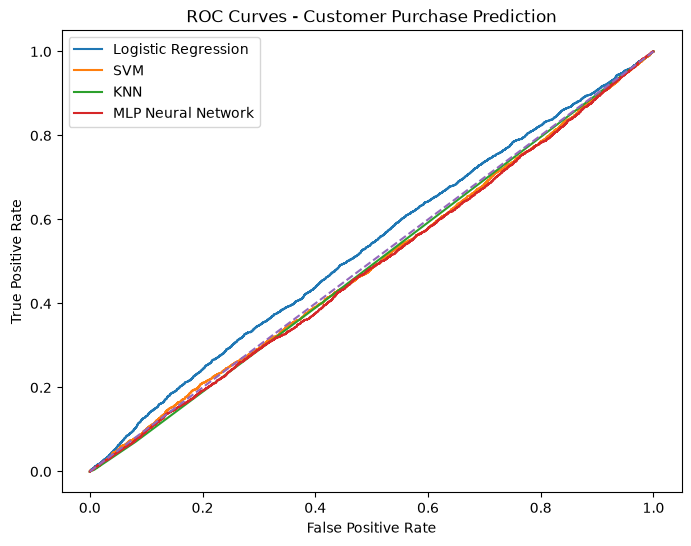

In [92]:
from sklearn.metrics import roc_curve, precision_recall_curve
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_prob,
    "SVM": svm_prob,
    "KNN": knn_prob,
    "MLP Neural Network": mlp_prob
}

# ROC Curve
plt.figure(figsize=(8, 6))

for name, prob in models.items():
    fpr, tpr, _ = roc_curve(y_test_enhanced, prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Customer Purchase Prediction")
plt.legend()
plt.show()

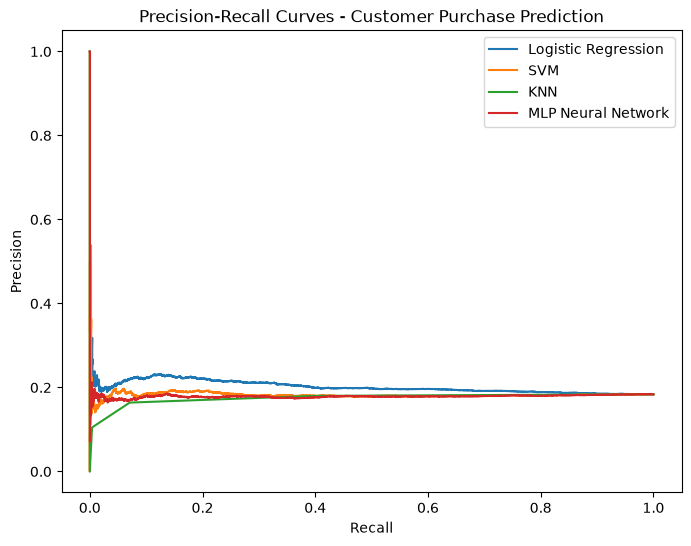

In [93]:
# Precision-Recall Curve
plt.figure(figsize=(8, 6))

for name, prob in models.items():
    precision, recall, _ = precision_recall_curve(y_test_enhanced, prob)
    plt.plot(recall, precision, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Customer Purchase Prediction")
plt.legend()
plt.show()

In [94]:
for name, prob in models.items():
    print(f"\n===== {name} =====")
    print(pd.Series(prob).describe())


===== Logistic Regression =====
count    17666.000000
mean         0.522343
std          0.020038
min          0.406384
25%          0.510249
50%          0.521732
75%          0.533326
max          0.630086
dtype: float64

===== SVM =====
count    17666.000000
mean         0.095067
std          0.000022
min          0.094975
25%          0.095053
50%          0.095070
75%          0.095084
max          0.095131
dtype: float64

===== KNN =====
count    17666.000000
mean         0.098755
std          0.132385
min          0.000000
25%          0.000000
50%          0.000000
75%          0.200000
max          0.800000
dtype: float64

===== MLP Neural Network =====
count    17666.000000
mean         0.084716
std          0.030025
min          0.002643
25%          0.064838
50%          0.083494
75%          0.102025
max          0.235426
dtype: float64


In [95]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for name, prob in models.items():
    print(f"\n{name}")

    for threshold in thresholds:
        predictions = (prob >= threshold).astype(int)
        print(
            f"Threshold {threshold}: "
            f"{predictions.sum()} predicted as class 1"
        )


Logistic Regression
Threshold 0.1: 17666 predicted as class 1
Threshold 0.2: 17666 predicted as class 1
Threshold 0.3: 17666 predicted as class 1
Threshold 0.4: 17666 predicted as class 1
Threshold 0.5: 15776 predicted as class 1

SVM
Threshold 0.1: 0 predicted as class 1
Threshold 0.2: 0 predicted as class 1
Threshold 0.3: 0 predicted as class 1
Threshold 0.4: 0 predicted as class 1
Threshold 0.5: 0 predicted as class 1

KNN
Threshold 0.1: 7193 predicted as class 1
Threshold 0.2: 7193 predicted as class 1
Threshold 0.3: 1402 predicted as class 1
Threshold 0.4: 1402 predicted as class 1
Threshold 0.5: 124 predicted as class 1

MLP Neural Network
Threshold 0.1: 4828 predicted as class 1
Threshold 0.2: 20 predicted as class 1
Threshold 0.3: 0 predicted as class 1
Threshold 0.4: 0 predicted as class 1
Threshold 0.5: 0 predicted as class 1


In [96]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:

    pred = (logistic_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_enhanced,
            pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_enhanced,
            pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_enhanced,
            pred,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1-Score
0,0.1,0.183913,1.000000,0.310686
1,0.2,0.183913,1.000000,0.310686
2,0.3,0.183913,1.000000,0.310686
3,0.4,0.183913,1.000000,0.310686
4,0.5,0.185281,0.899661,0.307280


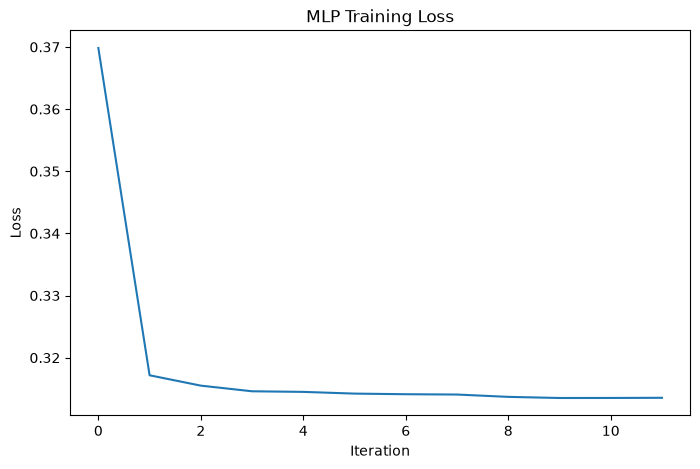

In [97]:
plt.figure(figsize=(8, 5))

plt.plot(mlp_model.loss_curve_)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("MLP Training Loss")
plt.show()

In [98]:
print("Iterations:", mlp_model.n_iter_)
print("Final loss:", mlp_model.loss_)

Iterations: 12
Final loss: 0.313549123049729


In [99]:
from sklearn.neural_network import MLPClassifier

mlp_model_2 = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=15,
    random_state=42
)

mlp_model_2.fit(
    X_train_enhanced_scaled,
    y_train_enhanced
)

mlp_pred_2 = mlp_model_2.predict(
    X_test_enhanced_scaled
)

mlp_prob_2 = mlp_model_2.predict_proba(
    X_test_enhanced_scaled
)[:, 1]

In [100]:
print(y_train_enhanced.value_counts())
print(y_train_enhanced.value_counts(normalize=True) * 100)

print(y_test_enhanced.value_counts())
print(y_test_enhanced.value_counts(normalize=True) * 100)

Purchased_Within_30_Days
0.0    64198
1.0     6744
Name: count, dtype: int64
Purchased_Within_30_Days
0.0    90.493643
1.0     9.506357
Name: proportion, dtype: float64
Purchased_Within_30_Days
0.0    14417
1.0     3249
Name: count, dtype: int64
Purchased_Within_30_Days
0.0    81.60874
1.0    18.39126
Name: proportion, dtype: float64


In [101]:
feature_target_corr = (
    train_data_enhanced[ml_features + ["Purchased_Within_30_Days"]]
    .corr()["Purchased_Within_30_Days"]
    .sort_values(ascending=False)
)

print(feature_target_corr)

Purchased_Within_30_Days          1.000000
Customer_Lifetime_Days            0.012460
Average_Days_Between_Purchases    0.006492
Previous_Order_Count              0.006009
Median_Days_Between_Purchases     0.004615
Days_Since_Previous_Purchase      0.004524
Quantity_Last_30_Days             0.003798
Previous_Total_Spending           0.001656
Orders_Last_30_Days               0.000476
Quantity_Last_60_Days            -0.000234
Orders_Last_7_Days               -0.001166
Spending_Last_30_Days            -0.001405
Orders_Last_60_Days              -0.001525
Quantity_Last_90_Days            -0.004064
Purchase_Frequency               -0.004338
Orders_Last_90_Days              -0.004480
Spending_Last_60_Days            -0.004727
Previous_Purchase_Quantity       -0.004733
Spending_Last_90_Days            -0.006177
Previous_Average_Order_Value     -0.006843
Previous_Purchase_Amount         -0.008486
Name: Purchased_Within_30_Days, dtype: float64
